# BIOT 6900 · Module 9 — Notebook 3 (GRADED)
## Clinical NLP on your own disease: build it, then catch the leakage
**Week 9 · Part III · this is the graded assignment**

> **⚠️ SYNTHETIC.** You design a synthetic patient population for a disease of your choice, run the full pipeline on it, and then do the hard part: look at what the model learned and separate genuine early signal from leakage.

You configure your disease's clinical picture (which findings are genuine early signals, which are interventions done to deteriorating patients). The notebook builds a cohort and notes from your choices, extracts features, trains a model, and reports permutation importance. **It also injects two clinical features you did not configure** — you must diagnose each as signal or leakage from the output.

**What is graded (course 60 / 40):** 60% execution (your config is clinically sensible, the notebook runs, the pipeline is correct) and **40% interpretation** (Part D: correctly sorting signal from leakage and defending it). See the assignment sheet for the rubric.

**How to run:** `Kernel → Restart & Run All`. It uses only `pandas` + `scikit-learn`.

## The engine (provided, do not edit)
Run this cell and move on. It defines the assertion engine, the cohort/notes generator, and the model helpers.

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# --- ConText assertion engine (from Notebook 2) ---
NEG_PRE  = ["no evidence of", "no acute", "denies", "denied", "without", "negative for", "ruled out for", "r/o", "no "]
NEG_POST = ["ruled out", "was negative", "is negative", "unlikely", "resolved"]
PSEUDO   = ["no change", "no increase", "no further", "not only", "cannot be ruled out", "gram negative"]
FAM      = ["mother", "father", "sister", "brother", "parent", "family history", "fh "]
HIST     = ["history of", "h/o", "hx of", "prior", "previous", "status post", "s/p", "chronic"]
HYPO     = ["if ", "would ", "should ", "to prevent", "risk of", "monitor for"]
def _sents(t): return [s.strip() for s in re.split(r"[.;\n]", t) if s.strip()]
def assertion(term, text):
    for sent in _sents(text):
        low = sent.lower()
        m = re.search(r"\b" + re.escape(term.lower()) + r"\b", low)
        if not m: continue
        pos = m.start(); pseudo = any(p in low for p in PSEUDO)
        pre = low[max(0, pos-60):pos]; post = low[pos+len(term):pos+len(term)+45]
        if any(x in low for x in FAM): return "family"
        if any(x in pre for x in HYPO): return "hypothetical"
        if not pseudo and (any(x in pre for x in NEG_PRE) or any(x in post for x in NEG_POST)): return "absent"
        if any(x in pre for x in HIST): return "historical"
        return "present"
    return None

def concept_present(synonyms, note_texts):
    for v in synonyms:
        for t in note_texts:
            if assertion(v, t) == "present":
                return 1
    return 0

# two features injected that you did NOT configure (diagnose them in Part D):
WILDCARDS = {
    "lactate_not_clearing": ["failing to clear", "not clearing"],
    "renal_replacement":    ["dialysis", "renal replacement therapy"],
}

def build_world(cfg, seed=2024, N=400):
    rng = np.random.default_rng(seed)
    age = rng.integers(40, 92, N); sex = rng.choice(["M", "F"], N)
    lactate = rng.normal(2.2, 1.3, N).clip(0.5, 14); creatinine = rng.normal(1.1, 0.6, N).clip(0.3, 9)
    sig_names = list(cfg["signals"]); con_names = list(cfg["consequences"])
    sig_present = {s: rng.random(N) < rng.uniform(0.18, 0.30) for s in sig_names}
    w_sig = rng.random(N) < 0.22                               # wildcard SIGNAL (a cause)
    logit = -2.3 + 0.045*(age-65) + 0.55*(lactate-2) + 0.3*(creatinine-1) + 0.55*w_sig
    for s in sig_names: logit = logit + 0.6*sig_present[s]
    died = (rng.random(N) < 1/(1+np.exp(-logit))).astype(int)
    w_leak = ((died == 1) & (rng.random(N) < 0.5)) | ((died == 0) & (rng.random(N) < 0.10))  # wildcard LEAK

    def notes_for(i):
        adm = [f"{age[i]}{sex[i]} admitted to the ICU.", f"Lactate {lactate[i]:.1f}, creatinine {creatinine[i]:.1f}."]
        for s in sig_names:
            syns = cfg["signals"][s]
            if sig_present[s][i]: adm.append(f"Clinical note: {rng.choice(syns)} present.")
            elif rng.random() < 0.25: adm.append(f"No evidence of {syns[0]}.")
        if w_sig[i]: adm.append("Lactate failing to clear despite resuscitation.")
        if rng.random() < 0.2: adm.append("History of MI, no acute chest pain.")
        prog = ["Progress note, hospital day 2."]
        if rng.random() < 0.15: prog.append("Family history of diabetes.")
        disch = ["Discharge / final note."]
        if died[i]:
            for c in con_names:
                if rng.random() < 0.5: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Required renal replacement therapy (dialysis).")
        else:
            for c in con_names:
                if rng.random() < 0.10: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Brief dialysis for contrast, since stopped.")
            disch.append(rng.choice(["Tolerating diet, ambulating.", "Stable for discharge."]))
        return [" ".join(adm), " ".join(prog), " ".join(disch)]

    NOTES = [notes_for(i) for i in range(N)]
    struct = pd.DataFrame({"subject_id": np.arange(1, N+1), "age": age, "sex": sex,
                           "lactate": lactate.round(1), "creatinine": creatinine.round(1), "died": died})
    struct.loc[rng.random(N) < 0.15, "lactate"] = np.nan
    return struct, NOTES

def cv_auroc(df, cols):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

def perm_importance(df, cols):
    X, y = df[cols].values, df["died"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
    return pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)

print("engine loaded.")

engine loaded.


## Part A — Configure your disease  (TODO)
Replace the EXAMPLE config with **your own disease**. You need:
- 2–3 **signals**: genuine, *early* findings that are **causes** of deterioration (present before things go wrong).
- 2–3 **consequences**: interventions or actions taken *because* a patient is deteriorating. These are your planted leakage.
- For each, give a few **synonyms / abbreviations** (the notes will use them at random, so normalization matters).

Choosing these well is a clinical-reasoning task, and it is graded. A cause belongs in `signals`; a treatment or end-of-life decision belongs in `consequences`.

In [2]:
# ======== PDAC configuration (Mohammed Sharukh) ========
# Outcome modelled by the engine: in-hospital death after ICU admission.
CONFIG = {
    "disease": "Pancreatic ductal adenocarcinoma (PDAC)",
    "signals": {        # genuine EARLY signals: disease processes present on admission (causes)
        "cachexia":            ["cachexia", "cachectic", "unintentional weight loss", "muscle wasting", "sarcopenia"],
        "biliary_obstruction": ["biliary obstruction", "obstructive jaundice", "hyperbilirubinemia", "cholangitis"],
        "rising_ca19_9":       ["rising ca 19-9", "ca 19-9 rising", "rising ca19-9", "tumor marker rising"],
    },
    "consequences": {   # decisions made BECAUSE the patient is deteriorating (planted LEAKAGE)
        "comfort_care":       ["comfort care", "hospice referral", "transitioned to hospice", "cmo"],
        "dnr_order":          ["dnr", "dnr/dni", "do not resuscitate", "code status changed to dnr"],
        "chemo_discontinued": ["chemotherapy discontinued", "folfirinox stopped", "gemcitabine held", "best supportive care"],
    },
}

SEED = 2019251       # student ID 002019251 (leading zeros dropped: Python rejects them in int literals)
# ========================================================

struct, NOTES = build_world(CONFIG, seed=SEED, N=400)
print("#"*70)
print(f"# SYNTHETIC cohort for: {CONFIG['disease']}")
print(f"# 400 patients, 3 notes each. Mortality prevalence = {struct.died.mean():.2f}")
print("#"*70)
print("Example patient notes:")
for tag, t in zip(["admit ", "day 2 ", "final "], NOTES[0]):
    print(f"  [{tag}] {t}")

######################################################################
# SYNTHETIC cohort for: Pancreatic ductal adenocarcinoma (PDAC)
# 400 patients, 3 notes each. Mortality prevalence = 0.21
######################################################################
Example patient notes:
  [admit ] 80M admitted to the ICU. Lactate 2.1, creatinine 2.0. Clinical note: sarcopenia present.
  [day 2 ] Progress note, hospital day 2.
  [final ] Discharge / final note. Cmo. Folfirinox stopped. Required renal replacement therapy (dialysis).


## Part B — Extract features  (TODO)
Assemble every concept to extract: your signals, your consequences, and the two injected wildcards. Then run the extractor across all 400 patients.

In [3]:
# the two injected features you did NOT configure are added here for you:
ALL_CONCEPTS = {**CONFIG["signals"], **CONFIG["consequences"], **WILDCARDS}

feat = pd.DataFrame({"subject_id": struct.subject_id})
for name, syns in ALL_CONCEPTS.items():
    feat[name] = [concept_present(syns, NOTES[i]) for i in range(400)]

print("Patients with each concept asserted PRESENT:")
print(feat.drop(columns="subject_id").sum().to_string())

Patients with each concept asserted PRESENT:
cachexia                107
biliary_obstruction      81
rising_ca19_9            81
comfort_care             68
dnr_order                82
chemo_discontinued       64
lactate_not_clearing     94
renal_replacement        76


Sanity check: compare naive keyword counting to assertion-aware counting for one of your signals.

In [4]:
one_signal = list(CONFIG["signals"])[0]
syns = CONFIG["signals"][one_signal]
naive = sum(int(any(re.search(r"\b"+re.escape(v)+r"\b", " ".join(NOTES[i]), re.I) for v in syns)) for i in range(400))
aware = int(feat[one_signal].sum())
print(f"{one_signal}:  naive keyword count = {naive}   assertion-aware = {aware}")

cachexia:  naive keyword count = 191   assertion-aware = 107


**Part B check (my note):**
- All 8 concepts were extracted for all 400 patients. Counts range from 64 to 107, which is plausible for an 18–30% signal prevalence and a 21% death rate.
- For **cachexia**, the naive keyword count is **191** and the assertion-aware count is **107**.
- The 84 extra naive hits are negated mentions ("No evidence of cachexia"). Keyword search counts them as positives; the assertion engine correctly marks them absent.


## Part C — Model and importance  (TODO)
Build the feature matrix, then **declare which of YOUR concepts you planted as leakage**. Do not include the wildcards yet — you have to find those in Part D.

In [5]:
df = struct.merge(feat, on="subject_id")
df["sex_F"] = (df.sex == "F").astype(int)
struct_cols = ["age", "sex_F", "lactate", "creatinine"]
concept_cols = list(ALL_CONCEPTS)
all_cols = struct_cols + concept_cols

# TODO: list the concepts YOU configured as consequences (your planted leakage)
declared_leak = list(CONFIG["consequences"])     # comfort_care, dnr_order, chemo_discontinued

m, sd   = cv_auroc(df, all_cols)
mh, sdh = cv_auroc(df, [c for c in all_cols if c not in declared_leak])
print(f"CV AUROC   all features = {m:.3f} ± {sd:.3f}")
print(f"CV AUROC   your declared leakage removed = {mh:.3f} ± {sdh:.3f}")

CV AUROC   all features = 0.917 ± 0.022
CV AUROC   your declared leakage removed = 0.853 ± 0.024


comfort_care            0.092
age                     0.050
renal_replacement       0.048
dnr_order               0.026
rising_ca19_9           0.014
chemo_discontinued      0.013
creatinine              0.000
biliary_obstruction    -0.001
lactate_not_clearing   -0.002
sex_F                  -0.009
cachexia               -0.009
lactate                -0.024


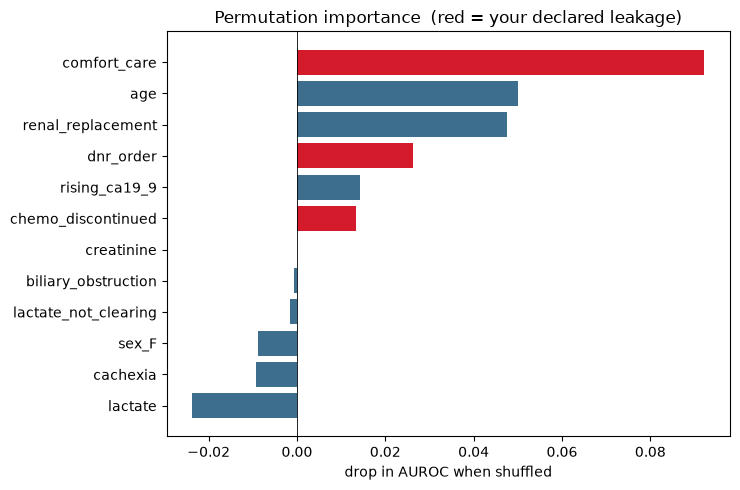

In [6]:
imp = perm_importance(df, all_cols)
print(imp.round(3).to_string())

order = imp.sort_values()
leakset = set(declared_leak)
colors = ["#D41B2C" if c in leakset else "#3E6E8E" for c in order.index]
plt.figure(figsize=(7.5, 5))
plt.barh(order.index, order.values, color=colors)
plt.axvline(0, color="black", linewidth=0.6)
plt.title("Permutation importance  (red = your declared leakage)")
plt.xlabel("drop in AUROC when shuffled"); plt.tight_layout(); plt.show()

## Part D — Catch the leakage and interpret  (GRADED, the 40%)
Now the real work. Answer each prompt in the markdown cell that follows it. Use the permutation importance and the AUROC numbers as evidence, and clinical reasoning (cause vs consequence) as the argument.

### D1. Read the importance plot
List the features at the **top** of the permutation-importance ranking. For each, say whether it is genuine early **signal** or **leakage**, and give a one-sentence clinical reason (is it a cause the patient had, or a consequence of them deteriorating?).

> *Your answer:*

Four of the top six features are leakage. Only age and rising CA 19-9 are genuine signals the patient had before deteriorating.

| Rank | Feature | Importance | Call | Clinical reason |
|---|---|---|---|---|
| 1 | comfort_care | 0.092 | **Leakage** | Hospice/comfort care is chosen once clinicians expect death, so it records the outcome rather than predicting it. |
| 2 | age | 0.050 | Signal | Age is fixed at admission and raises baseline risk of death from PDAC and its complications. |
| 3 | renal_replacement | 0.048 | **Leakage** | Dialysis is an escalation started after the kidneys fail during the stay; it appears only in the discharge note. |
| 4 | dnr_order | 0.026 | **Leakage** | Code status is changed to DNR in response to decline. |
| 5 | rising_ca19_9 | 0.014 | Signal | A rising tumour marker reflects progressing disease already present on admission. |
| 6 | chemo_discontinued | 0.013 | **Leakage** | FOLFIRINOX/gemcitabine is stopped because the patient can no longer tolerate it. |

Small negative importances (lactate −0.024, cachexia −0.009) mean shuffling changed nothing on the 120-patient test split. They are noise, not evidence that those features hurt the model.


### D2. Hunt the hidden leak
Your 'declared leakage removed' AUROC is probably still high. That is a clue you missed a leak. Two features were injected that you did not configure: **`lactate_not_clearing`** and **`renal_replacement`**. From the importance plot and clinical reasoning, classify each as signal or leakage, and justify. Then add any you judge to be leakage to the set below and re-run.

> *Your answer:*

With my three consequences removed the AUROC was still 0.853, so a leak remained.

**`renal_replacement` is leakage and was the hidden leak.**
- It ranks 3rd (0.048), above every genuine PDAC signal.
- It is present in 56.6% of deaths but only 9.1% of survivors, and it is written only in the discharge note (see the evidence cell below).
- Clinically, dialysis/CRRT is an intervention done to a patient whose kidneys are already failing: a consequence of deterioration, not a cause.
- On its own it scores AUROC 0.737, almost the whole honest model (0.746).
- Even survivors' "brief dialysis for contrast, since stopped" is asserted present, because the rule engine cannot tell a resolved intervention from an ongoing one.

I added it to `final_leak`.

**`lactate_not_clearing` is a genuine (late) signal, so I kept it.**
- It is a physiological measurement of failed tissue perfusion, recorded in the admission note before any end-of-life decision.
- It is only modestly enriched in deaths (26.5% vs 22.7%) and its importance is near zero (−0.002 full model, 0.003 honest model).

That is how a weak true cause behaves; a leak would be strongly concentrated in the patients who died. Removing it would discard real information without making the model any more honest.


In [7]:
# TODO: your FINAL leak set = your declared leakage + any wildcard you caught
final_leak = declared_leak + ["renal_replacement"]     # D2: renal_replacement is leakage; lactate_not_clearing kept as signal

m_all, _    = cv_auroc(df, all_cols)
m_honest, _ = cv_auroc(df, [c for c in all_cols if c not in final_leak])
print(f"AUROC with everything     = {m_all:.3f}")
print(f"AUROC, all leakage removed = {m_honest:.3f}")

# does a wildcard you kept as signal actually matter once leakage is gone?
honest_imp = perm_importance(df, [c for c in all_cols if c not in final_leak])
print("\nHonest-model importance (top 6):")
print(honest_imp.head(6).round(3).to_string())

AUROC with everything     = 0.917
AUROC, all leakage removed = 0.746

Honest-model importance (top 6):
age                     0.173
rising_ca19_9           0.032
biliary_obstruction     0.018
lactate                 0.016
creatinine              0.009
lactate_not_clearing    0.003


### Supporting evidence for D2 (added by me)
For each concept: % present among deaths vs survivors, and which note it is asserted in. Leakage lives in the discharge note and is concentrated in deaths; signals live in the admission note.


In [8]:
rows = []
for name, syns_c in ALL_CONCEPTS.items():
    where = {"admit": 0, "day2": 0, "final": 0}
    for i in range(400):
        for tag, t in zip(where, NOTES[i]):
            if concept_present(syns_c, [t]): where[tag] += 1
    rows.append(dict(feature=name,
                     pct_died=round(100*df.loc[df.died == 1, name].mean(), 1),
                     pct_survived=round(100*df.loc[df.died == 0, name].mean(), 1),
                     in_admit_note=where["admit"], in_final_note=where["final"]))
print(pd.DataFrame(rows).set_index("feature").to_string())

print(f"\nAUROC, structured features only        = {cv_auroc(df, struct_cols)[0]:.3f}")
print(f"AUROC, structured + my PDAC signals     = {cv_auroc(df, struct_cols + list(CONFIG['signals']))[0]:.3f}")
print(f"AUROC, leakage features only            = {cv_auroc(df, final_leak)[0]:.3f}")
print(f"AUROC, renal_replacement alone          = {cv_auroc(df, ['renal_replacement'])[0]:.3f}")
m_h, sd_h = cv_auroc(df, [c for c in all_cols if c not in final_leak])
print(f"AUROC, all leakage removed (mean ± SD)  = {m_h:.3f} ± {sd_h:.3f}")


                      pct_died  pct_survived  in_admit_note  in_final_note
feature                                                                   
cachexia                  36.1          24.3            107              0
biliary_obstruction       28.9          18.0             81              0
rising_ca19_9             34.9          16.4             81              0
comfort_care              51.8           7.9              0             68
dnr_order                 51.8          12.3              0             82
chemo_discontinued        45.8           8.2              0             64
lactate_not_clearing      26.5          22.7             94              0
renal_replacement         56.6           9.1              0             76

AUROC, structured features only        = 0.713
AUROC, structured + my PDAC signals     = 0.748
AUROC, leakage features only            = 0.897
AUROC, renal_replacement alone          = 0.737
AUROC, all leakage removed (mean ± SD)  = 0.746 ± 0.037


### D3. Quantify the damage
Report the AUROC with everything, with your declared leakage removed, and with all leakage removed (including any wildcard you caught). What does the size of each drop tell you about how much of the model's apparent skill was leakage?

> *Your answer:*

| Model | CV AUROC | Drop |
|---|---|---|
| Everything | 0.917 ± 0.022 | — |
| Declared leakage removed | 0.853 ± 0.024 | −0.064 |
| All leakage removed (+ `renal_replacement`) | 0.746 ± 0.037 | −0.107 more (−0.171 total) |

- **First drop (−0.064).** My three consequences carried real but partly redundant leakage. With them gone, `renal_replacement` stood in for them, so the score stayed high.
- **Second drop (−0.107).** Removing the hidden leak cost more than removing the three declared ones first.
- **Share of skill that was leakage.** Measured as skill above chance (AUROC − 0.5), 0.417 fell to 0.246, so about 41% of the model's apparent skill was leakage.
- **The honest number is 0.746.** For comparison, the leakage features alone score 0.897, structured data alone 0.713, and adding my three PDAC signals lifts structured data to 0.748.
- **Not noise.** Each drop is several times the fold-to-fold SD.


### D4. Reality check
Pick your two strongest genuine signals. Would they actually be **documented early enough** to act on in a real chart? Name one way this synthetic cohort is unlike real clinical data (think about the lecture's documentation-bias and small-cohort points).

> *Your answer:*

My two strongest genuine signals in the honest model are **rising CA 19-9** (0.032) and **biliary obstruction** (0.018).

- **Rising CA 19-9: partly.** CA 19-9 is drawn at outpatient oncology visits every few cycles, so the trend lives in lab tables, not the ICU admission note. Notes usually state one value, and "rising" only appears when a clinician compares results.
- **Biliary obstruction: yes, but it gets relabelled.** Jaundice is often the presenting symptom, so it is documented very early. However, it is usually stented quickly and later written as "s/p ERCP stent", which this assertion engine would mark *historical* and miss.

**How this cohort is unlike real data.** Every signal is written once, in the admission note, with an exact synonym, and every consequence appears only in the discharge note. Real charts have copy-forward text, abbreviations and **documentation bias**: sicker patients get more notes, so simply being mentioned more often correlates with dying. The cohort is also **small** (400 patients, 83 deaths), so permutation importance from a 120-patient split is noisy, which is why some true signals show small negative values.

A deployable model would only use notes written before a fixed prediction time, which removes discharge-note leaks by design.


## What to submit
- This notebook, run top to bottom (`Kernel → Restart & Run All`), committed to your biot6900 repo.
- Your written answers to D1–D4 in the markdown cells above.
- A short README noting your disease and anything that did not work.

Then post your repo link on Canvas. Grading follows the assignment sheet (course 60 / 40).